In [1]:

import sqlite3
import pandas as pd

# File locations
csv_path = r"C:\Users\sapka\Downloads\retail_cleaned_for_sql.csv"
db_path = r"C:\Users\sapka\Downloads\retail_analytics.db"

# Connect to SQLite (creates the database if it doesn't exist)
conn = sqlite3.connect(db_path)

# Import CSV into a SQL table
for chunk in pd.read_csv(csv_path, chunksize=50000):
    chunk.to_sql(
        "retail_transactions",
        conn,
        if_exists="append",
        index=False
    )

print("CSV imported into SQLite successfully!")

# Verify the number of rows
result = pd.read_sql_query(
    "SELECT COUNT(*) AS total_rows FROM retail_transactions",
    conn
)

display(result)

print("Database location:", db_path)


CSV imported into SQLite successfully!


,total_rows
0,1033036


Database location: C:\Users\sapka\Downloads\retail_analytics.db


In [2]:

query = """
SELECT
    Country,
    COUNT(*) AS total_transactions
FROM retail_transactions
GROUP BY Country
ORDER BY total_transactions DESC
LIMIT 10;
"""

display(pd.read_sql_query(query, conn))


,Country,total_transactions
0,United Kingdom,948321
1,EIRE,17667
2,Germany,17339
3,France,14025
4,Netherlands,5137
5,Spain,3754
6,Switzerland,3175
7,Belgium,3110
8,Portugal,2528
9,Australia,1890


In [8]:
query="""
SELECT 
    Country,
    ROUND(SUM(Quantity * Price),2) AS Total_Revenue,
    SUM(Quantity) AS Total_Quantity,
    COUNT(DISTINCT Invoice) AS Unique_Invoice
FROM retail_transactions 
WHERE Quantity>0
    AND
    Price>0
    AND Cast(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY Country
ORDER BY Total_Revenue DESC
LIMIT 10;
"""
display(pd.read_sql_query(query,conn))

,Country,Total_Revenue,Total_Quantity,Unique_Invoice
0,United Kingdom,17410196.12,9187753,36535
1,EIRE,658767.31,336329,626
2,Netherlands,554038.09,383879,228
3,Germany,425019.71,225154,789
4,France,350456.09,271901,622
5,Australia,169283.46,103759,95
6,Spain,108332.49,50307,154
7,Switzerland,100685.59,52762,93
8,Sweden,91869.82,88633,105
9,Denmark,68580.69,237471,43


In [9]:

query = """
SELECT
    strftime('%Y-%m', InvoiceDate) AS Month,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    SUM(Quantity) AS Total_Quantity,
    COUNT(DISTINCT Invoice) AS Unique_Invoices
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY strftime('%Y-%m', InvoiceDate)
ORDER BY Month;
"""

monthly_sql = pd.read_sql_query(query, conn)
display(monthly_sql.head(15))


,Month,Total_Revenue,Total_Quantity,Unique_Invoices
0,2009-12,822483.95,425461,1682
1,2010-01,651155.11,390672,1105
2,2010-02,551504.73,381879,1201
3,2010-03,830915.26,526026,1681
4,2010-04,678875.25,366705,1462
5,2010-05,657705.50,395868,1500
6,2010-06,749537.31,406820,1645
7,2010-07,648810.27,337895,1529
8,2010-08,695251.91,472380,1425
9,2010-09,921696.99,583864,1839


In [10]:
query="""
SELECT 
    StockCode,
    Description,
    ROUND(SUM(Quantity * Price),2) AS Total_Revenue,
    SUM(Quantity) AS Total_Quantity,
    COUNT(DISTINCT Invoice) AS Unique_Invoice
FROM retail_transactions 
WHERE Quantity>0
    AND
    Price>0
    AND Cast(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY StockCode,Description
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

top_products_sql=display(pd.read_sql_query(query,conn))
top_products_sql

,StockCode,Description,Total_Revenue,Total_Quantity,Unique_Invoice
0,M,Manual,339226.24,9629,784
1,22423,REGENCY CAKESTAND 3 TIER,330590.32,26478,3918
2,DOT,DOTCOM POSTAGE,309854.11,1415,1415
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,257546.20,94142,5356
4,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
5,47566,PARTY BUNTING,148318.28,28200,2674
6,85099B,JUMBO BAG RED RETROSPOT,145961.83,77280,3245
7,84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,80082,2807
8,POST,POSTAGE,125682.42,5363,1851
9,22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,35084,2018


In [11]:

query = """
SELECT
    "Customer ID",
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    SUM(Quantity) AS Total_Quantity,
    COUNT(DISTINCT Invoice) AS Unique_Invoices
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
  AND "Customer ID" IS NOT NULL
GROUP BY "Customer ID"
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

top_customers_sql = pd.read_sql_query(query, conn)
display(top_customers_sql)


,Customer ID,Total_Revenue,Total_Quantity,Unique_Invoices
0,18102.0,580987.04,181645,145
1,14646.0,528602.52,367193,151
2,14156.0,313437.62,164325,156
3,14911.0,291420.81,147972,398
4,17450.0,244784.25,83914,51
5,13694.0,195640.69,188201,143
6,17511.0,172132.87,117174,60
7,16446.0,168472.50,80997,2
8,16684.0,147142.77,104810,55
9,12415.0,144458.37,91447,28


In [12]:

query = """
WITH customer_orders AS (
    SELECT
        "Customer ID",
        COUNT(DISTINCT Invoice) AS invoice_count
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
      AND "Customer ID" IS NOT NULL
    GROUP BY "Customer ID"
)
SELECT
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN invoice_count >= 2 THEN 1 ELSE 0 END)
        AS Repeat_Customers,
    SUM(CASE WHEN invoice_count = 1 THEN 1 ELSE 0 END)
        AS One_Time_Customers,
    ROUND(
        100.0 * SUM(
            CASE WHEN invoice_count >= 2 THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS Repeat_Customer_Rate
FROM customer_orders;
"""

repeat_sql = pd.read_sql_query(query, conn)
display(repeat_sql)


,Total_Customers,Repeat_Customers,One_Time_Customers,Repeat_Customer_Rate
0,5878,4255,1623,72.39


In [13]:

query = """
SELECT
    Country,
    COUNT(DISTINCT "Customer ID") AS Unique_Customers,
    COUNT(DISTINCT Invoice) AS Unique_Invoices,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
  AND "Customer ID" IS NOT NULL
GROUP BY Country
ORDER BY Unique_Customers DESC
LIMIT 10;
"""

country_customers_sql = pd.read_sql_query(query, conn)
display(country_customers_sql)


,Country,Unique_Customers,Unique_Invoices,Total_Revenue
0,United Kingdom,5350,33541,14389234.92
1,Germany,107,789,425019.71
2,France,95,614,348768.96
3,Spain,41,154,108332.49
4,Belgium,29,149,65387.82
5,Portugal,24,93,55554.78
6,Switzerland,22,90,100061.94
7,Netherlands,22,228,554038.09
8,Sweden,19,104,91515.82
9,Italy,17,65,32108.17


In [14]:

query = """
SELECT
    Country,
    COUNT(DISTINCT Invoice) AS Unique_Invoices,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    ROUND(
        SUM(Quantity * Price) * 1.0 /
        COUNT(DISTINCT Invoice), 2
    ) AS Average_Order_Value
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY Country
HAVING COUNT(DISTINCT Invoice) >= 10
ORDER BY Average_Order_Value DESC
LIMIT 10;
"""

country_aov_sql = pd.read_sql_query(query, conn)
display(country_aov_sql)


,Country,Unique_Invoices,Total_Revenue,Average_Order_Value
0,Netherlands,228,554038.09,2429.99
1,Singapore,11,25317.06,2301.55
2,Australia,95,169283.46,1781.93
3,Denmark,43,68580.69,1594.90
4,Hong Kong,15,23685.52,1579.03
5,Japan,33,43023.91,1303.75
6,Norway,45,56322.50,1251.61
7,Israel,10,11328.81,1132.88
8,Switzerland,93,100685.59,1082.64
9,Greece,18,19096.19,1060.90


In [15]:

query = """
SELECT
    strftime('%Y', InvoiceDate) AS Year,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    COUNT(DISTINCT Invoice) AS Unique_Invoices,
    COUNT(DISTINCT "Customer ID") AS Unique_Customers,
    ROUND(
        SUM(Quantity * Price) * 1.0 /
        COUNT(DISTINCT Invoice), 2
    ) AS Average_Order_Value
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY strftime('%Y', InvoiceDate)
ORDER BY Year;
"""

yearly_revenue_sql = pd.read_sql_query(query, conn)
display(yearly_revenue_sql)


,Year,Total_Revenue,Unique_Invoices,Unique_Customers,Average_Order_Value
0,2009,822483.95,1682,955,488.99
1,2010,9833100.42,19994,4231,491.80
2,2011,9820676.07,18401,4219,533.70


In [16]:

query = """
SELECT
    StockCode,
    Description,
    SUM(Quantity) AS Total_Quantity_Sold,
    COUNT(DISTINCT Invoice) AS Unique_Invoices,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
  AND Description IS NOT NULL
GROUP BY StockCode, Description
ORDER BY Total_Quantity_Sold DESC
LIMIT 10;
"""

top_products_quantity_sql = pd.read_sql_query(query, conn)
display(top_products_quantity_sql)


,StockCode,Description,Total_Quantity_Sold,Unique_Invoices,Total_Revenue
0,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106139,1019,24445.61
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94142,5356,257546.20
2,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,1,168469.60
3,84879,ASSORTED COLOUR BIRD ORNAMENT,80082,2807,129324.49
4,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,247,81700.92
5,85099B,JUMBO BAG RED RETROSPOT,77280,3245,145961.83
6,17003,BROCADE RING PURSE,70369,456,14766.42
7,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56061,1993,28081.73
8,84991,60 TEATIME FAIRY CAKE CASES,54028,2127,27041.21
9,22197,SMALL POPCORN HOLDER,48561,1407,42699.89


In [17]:

query = """
SELECT
    strftime('%Y-%m', InvoiceDate) AS Month,
    COUNT(DISTINCT Invoice) AS Unique_Invoices,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    ROUND(
        SUM(Quantity * Price) * 1.0 /
        COUNT(DISTINCT Invoice), 2
    ) AS Average_Order_Value
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY strftime('%Y-%m', InvoiceDate)
ORDER BY Month;
"""

monthly_sales_sql = pd.read_sql_query(query, conn)
display(monthly_sales_sql)


,Month,Unique_Invoices,Total_Revenue,Average_Order_Value
0,2009-12,1682,822483.95,488.99
1,2010-01,1105,651155.11,589.28
2,2010-02,1201,551504.73,459.20
3,2010-03,1681,830915.26,494.30
4,2010-04,1462,678875.25,464.35
5,2010-05,1500,657705.50,438.47
6,2010-06,1645,749537.31,455.65
7,2010-07,1529,648810.27,424.34
8,2010-08,1425,695251.91,487.90
9,2010-09,1839,921696.99,501.19


In [18]:

query = """
SELECT
    COUNT(*) AS Total_Rows,

    SUM(
        CASE
            WHEN CAST(Invoice AS TEXT) LIKE 'C%'
            THEN 1 ELSE 0
        END
    ) AS Cancellation_Rows,

    SUM(
        CASE
            WHEN Quantity < 0
            THEN 1 ELSE 0
        END
    ) AS Negative_Quantity_Rows,

    SUM(
        CASE
            WHEN Price <= 0
            THEN 1 ELSE 0
        END
    ) AS Non_Positive_Price_Rows,

    ROUND(
        SUM(
            CASE
                WHEN Quantity < 0 OR CAST(Invoice AS TEXT) LIKE 'C%'
                THEN ABS(Quantity * Price)
                ELSE 0
            END
        ), 2
    ) AS Cancellation_Return_Value
FROM retail_transactions;
"""

quality_impact_sql = pd.read_sql_query(query, conn)
display(quality_impact_sql)



,Total_Rows,Cancellation_Rows,Negative_Quantity_Rows,Non_Positive_Price_Rows,Cancellation_Return_Value
0,1033036,19104,22496,6019,1462797.75


In [19]:

query = """
WITH customer_orders AS (
    SELECT
        "Customer ID",
        COUNT(DISTINCT Invoice) AS Invoice_Count,
        ROUND(SUM(Quantity * Price), 2) AS Customer_Revenue
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
      AND "Customer ID" IS NOT NULL
    GROUP BY "Customer ID"
)
SELECT
    CASE
        WHEN Invoice_Count = 1 THEN '1 invoice'
        WHEN Invoice_Count BETWEEN 2 AND 5 THEN '2-5 invoices'
        WHEN Invoice_Count BETWEEN 6 AND 10 THEN '6-10 invoices'
        ELSE 'More than 10 invoices'
    END AS Purchase_Frequency,
    COUNT(*) AS Number_Of_Customers,
    ROUND(SUM(Customer_Revenue), 2) AS Total_Revenue
FROM customer_orders
GROUP BY Purchase_Frequency
ORDER BY
    CASE Purchase_Frequency
        WHEN '1 invoice' THEN 1
        WHEN '2-5 invoices' THEN 2
        WHEN '6-10 invoices' THEN 3
        ELSE 4
    END;
"""

purchase_frequency_sql = pd.read_sql_query(query, conn)
display(purchase_frequency_sql)


,Purchase_Frequency,Number_Of_Customers,Total_Revenue
0,1 invoice,1623,560272.56
1,2-5 invoices,2454,2905362.90
2,6-10 invoices,925,2603222.51
3,More than 10 invoices,876,11305946.28


In [20]:

query = """
SELECT
    "Customer ID",
    COUNT(DISTINCT Invoice) AS Unique_Invoices,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    ROUND(
        SUM(Quantity * Price) * 1.0 /
        COUNT(DISTINCT Invoice), 2
    ) AS Average_Order_Value
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
  AND "Customer ID" IS NOT NULL
GROUP BY "Customer ID"
HAVING COUNT(DISTINCT Invoice) >= 5
ORDER BY Average_Order_Value DESC
LIMIT 10;
"""

top_customers_aov_sql = pd.read_sql_query(query, conn)
display(top_customers_aov_sql)


,Customer ID,Unique_Invoices,Total_Revenue,Average_Order_Value
0,13902.0,5,34095.26,6819.05
1,12346.0,12,77556.46,6463.04
2,12415.0,28,144458.37,5159.23
3,17450.0,51,244784.25,4799.69
4,18102.0,145,580987.04,4006.81
5,14088.0,16,64036.80,4002.30
6,14096.0,17,65164.79,3833.22
7,12753.0,6,21429.39,3571.57
8,14646.0,151,528602.52,3500.68
9,12409.0,7,23419.29,3345.61


In [21]:

query = """
WITH customer_revenue AS (
    SELECT
        "Customer ID",
        SUM(Quantity * Price) AS Total_Revenue
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
      AND "Customer ID" IS NOT NULL
    GROUP BY "Customer ID"
),
customer_segments AS (
    SELECT
        "Customer ID",
        Total_Revenue,
        CASE
            WHEN Total_Revenue < 500 THEN 'Low Spending'
            WHEN Total_Revenue < 2000 THEN 'Medium Spending'
            ELSE 'High Spending'
        END AS Customer_Segment
    FROM customer_revenue
)
SELECT
    Customer_Segment,
    COUNT(*) AS Number_Of_Customers,
    ROUND(SUM(Total_Revenue), 2) AS Total_Revenue,
    ROUND(AVG(Total_Revenue), 2) AS Average_Customer_Revenue
FROM customer_segments
GROUP BY Customer_Segment
ORDER BY
    CASE Customer_Segment
        WHEN 'Low Spending' THEN 1
        WHEN 'Medium Spending' THEN 2
        ELSE 3
    END;
"""

customer_segments_sql = pd.read_sql_query(query, conn)
display(customer_segments_sql)


,Customer_Segment,Number_Of_Customers,Total_Revenue,Average_Customer_Revenue
0,Low Spending,2066,529410.67,256.25
1,Medium Spending,2180,2324784.00,1066.41
2,High Spending,1632,14520609.60,8897.43


In [22]:

query = """
SELECT
    Invoice,
    InvoiceDate,
    "Customer ID",
    StockCode,
    Description,
    Quantity,
    Price,
    ROUND(Quantity * Price, 2) AS Revenue,
    Country
FROM retail_transactions
WHERE Quantity > 10000
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
ORDER BY Quantity DESC;
"""

unusual_quantity_sql = pd.read_sql_query(query, conn)
display(unusual_quantity_sql)


,Invoice,InvoiceDate,Customer ID,StockCode,Description,Quantity,Price,Revenue,Country
0,581483,2011-12-09 09:15:00,16446.0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,United Kingdom
1,541431,2011-01-18 10:01:00,12346.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,United Kingdom
2,497946,2010-02-15 11:57:00,13902.0,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2,Denmark
3,501534,2010-03-17 13:09:00,13902.0,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0,Denmark
4,501534,2010-03-17 13:09:00,13902.0,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0,Denmark
5,501534,2010-03-17 13:09:00,13902.0,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4,Denmark
6,501534,2010-03-17 13:09:00,13902.0,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0,Denmark


In [23]:

query = """
SELECT
    StockCode,
    Description,
    COUNT(DISTINCT Invoice) AS Unique_Invoices,
    SUM(Quantity) AS Total_Quantity_Sold,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    ROUND(
        SUM(Quantity * Price) * 1.0 /
        COUNT(DISTINCT Invoice), 2
    ) AS Revenue_Per_Invoice
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
  AND Description IS NOT NULL
GROUP BY StockCode, Description
HAVING COUNT(DISTINCT Invoice) >= 10
ORDER BY Revenue_Per_Invoice DESC
LIMIT 10;
"""

product_revenue_per_invoice_sql = pd.read_sql_query(query, conn)
display(product_revenue_per_invoice_sql)


,StockCode,Description,Unique_Invoices,Total_Quantity_Sold,Total_Revenue,Revenue_Per_Invoice
0,M,Manual,784,9629,339226.24,432.69
1,ADJUST,Adjustment by john on 26/01/2010 17,16,16,6563.50,410.22
2,23166,MEDIUM CERAMIC TOP STORAGE JAR,247,78033,81700.92,330.77
3,22833,HALL CABINET WITH 3 DRAWERS,13,120,4163.54,320.27
4,22656,VINTAGE BLUE KITCHEN CABINET,37,45,9290.00,251.08
5,22655,VINTAGE RED KITCHEN CABINET,53,76,12845.00,242.36
6,22828,REGENCY MIRROR WITH SHUTTERS,11,17,2565.00,233.18
7,DOT,DOTCOM POSTAGE,1415,1415,309854.11,218.98
8,84467,ENGLISH ROSE DESIGN QUILTED THROW,83,816,17477.66,210.57
9,22830,UTILTY CABINET WITH HOOKS,18,181,3760.71,208.93


In [24]:

query = """
SELECT
    StockCode,
    Description,
    COUNT(DISTINCT Invoice) AS Unique_Invoices,
    SUM(Quantity) AS Total_Quantity_Sold,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    ROUND(
        SUM(Quantity * Price) * 1.0 /
        COUNT(DISTINCT Invoice), 2
    ) AS Revenue_Per_Invoice
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
  AND Description IS NOT NULL
  AND UPPER(TRIM(Description)) NOT LIKE '%POSTAGE%'
  AND UPPER(TRIM(Description)) NOT LIKE '%ADJUSTMENT%'
  AND UPPER(TRIM(Description)) NOT LIKE 'MANUAL%'
GROUP BY StockCode, Description
HAVING COUNT(DISTINCT Invoice) >= 10
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

merchandise_products_sql = pd.read_sql_query(query, conn)
display(merchandise_products_sql)


,StockCode,Description,Unique_Invoices,Total_Quantity_Sold,Total_Revenue,Revenue_Per_Invoice
0,22423,REGENCY CAKESTAND 3 TIER,3918,26478,330590.32,84.38
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,5356,94142,257546.20,48.09
2,47566,PARTY BUNTING,2674,28200,148318.28,55.47
3,85099B,JUMBO BAG RED RETROSPOT,3245,77280,145961.83,44.98
4,84879,ASSORTED COLOUR BIRD ORNAMENT,2807,80082,129324.49,46.07
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,2018,35084,117760.29,58.35
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,247,78033,81700.92,330.77
7,79321,CHILLI LIGHTS,1135,15841,80540.88,70.96
8,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,756,31409,71300.40,94.31
9,85099F,JUMBO BAG STRAWBERRY,1830,36860,67985.77,37.15


In [25]:

query = """
SELECT
    Country,
    strftime('%Y', InvoiceDate) AS Year,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    COUNT(DISTINCT Invoice) AS Unique_Invoices
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY Country, strftime('%Y', InvoiceDate)
ORDER BY Country, Year;
"""

country_year_sql = pd.read_sql_query(query, conn)
display(country_year_sql)


,Country,Year,Total_Revenue,Unique_Invoices
0,Australia,2009,271.10,2
1,Australia,2010,31523.90,39
2,Australia,2011,137488.46,54
3,Austria,2009,1998.34,2
4,Austria,2010,11693.19,27
...,...,...,...,...
94,United Kingdom,2010,8407136.95,18368
95,United Kingdom,2011,8255661.87,16572
96,Unspecified,2010,6186.22,11
97,Unspecified,2011,4740.94,13


In [26]:

query = """
WITH country_year AS (
    SELECT
        Country,
        strftime('%Y', InvoiceDate) AS Year,
        SUM(Quantity * Price) AS Total_Revenue
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
      AND strftime('%Y', InvoiceDate) IN ('2010', '2011')
    GROUP BY Country, strftime('%Y', InvoiceDate)
),
country_comparison AS (
    SELECT
        Country,
        SUM(CASE WHEN Year = '2010'
                 THEN Total_Revenue ELSE 0 END) AS Revenue_2010,
        SUM(CASE WHEN Year = '2011'
                 THEN Total_Revenue ELSE 0 END) AS Revenue_2011
    FROM country_year
    GROUP BY Country
)
SELECT
    Country,
    ROUND(Revenue_2010, 2) AS Revenue_2010,
    ROUND(Revenue_2011, 2) AS Revenue_2011,
    ROUND(Revenue_2011 - Revenue_2010, 2) AS Revenue_Change,
    ROUND(
        100.0 * (Revenue_2011 - Revenue_2010) /
        Revenue_2010, 2
    ) AS Growth_Percentage
FROM country_comparison
WHERE Revenue_2010 > 0
  AND Revenue_2011 > 0
ORDER BY Growth_Percentage DESC
LIMIT 10;
"""

country_growth_sql = pd.read_sql_query(query, conn)
display(country_growth_sql)


,Country,Revenue_2010,Revenue_2011,Revenue_Change,Growth_Percentage
0,Lebanon,211.70,1693.88,1482.18,700.13
1,Singapore,4037.77,21279.29,17241.52,427.01
2,Australia,31523.90,137488.46,105964.56,336.14
3,Brazil,268.27,1143.60,875.33,326.29
4,Canada,1216.66,3666.38,2449.72,201.35
5,Finland,7723.18,21653.28,13930.10,180.37
6,Iceland,1323.32,3598.21,2274.89,171.91
7,Israel,3199.40,8129.41,4930.01,154.09
8,Japan,13312.61,29711.30,16398.69,123.18
9,Poland,3195.98,7086.49,3890.51,121.73


In [27]:

query = """
WITH country_revenue AS (
    SELECT
        Country,
        SUM(Quantity * Price) AS Total_Revenue
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
    GROUP BY Country
)
SELECT
    Country,
    ROUND(Total_Revenue, 2) AS Total_Revenue,
    ROUND(
        100.0 * Total_Revenue /
        SUM(Total_Revenue) OVER (), 2
    ) AS Revenue_Share_Percentage
FROM country_revenue
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

country_revenue_share_sql = pd.read_sql_query(query, conn)
display(country_revenue_share_sql)


,Country,Total_Revenue,Revenue_Share_Percentage
0,United Kingdom,17410196.12,85.03
1,EIRE,658767.31,3.22
2,Netherlands,554038.09,2.71
3,Germany,425019.71,2.08
4,France,350456.09,1.71
5,Australia,169283.46,0.83
6,Spain,108332.49,0.53
7,Switzerland,100685.59,0.49
8,Sweden,91869.82,0.45
9,Denmark,68580.69,0.33


In [28]:

query = """
WITH monthly_revenue AS (
    SELECT
        strftime('%Y-%m', InvoiceDate) AS Month,
        SUM(Quantity * Price) AS Total_Revenue
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
    GROUP BY strftime('%Y-%m', InvoiceDate)
)
SELECT
    Month,
    ROUND(Total_Revenue, 2) AS Total_Revenue,
    ROUND(
        100.0 * Total_Revenue /
        SUM(Total_Revenue) OVER (), 2
    ) AS Revenue_Share_Percentage
FROM monthly_revenue
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

monthly_revenue_share_sql = pd.read_sql_query(query, conn)
display(monthly_revenue_share_sql)


,Month,Total_Revenue,Revenue_Share_Percentage
0,2011-11,1503866.78,7.34
1,2010-11,1464293.14,7.15
2,2010-10,1161902.22,5.67
3,2011-10,1151263.73,5.62
4,2011-09,1056435.19,5.16
5,2010-09,921696.99,4.50
6,2010-03,830915.26,4.06
7,2009-12,822483.95,4.02
8,2010-12,821452.73,4.01
9,2011-05,769296.61,3.76


In [29]:

query = """
SELECT
    CASE CAST(strftime('%w', InvoiceDate) AS INTEGER)
        WHEN 0 THEN 'Sunday'
        WHEN 1 THEN 'Monday'
        WHEN 2 THEN 'Tuesday'
        WHEN 3 THEN 'Wednesday'
        WHEN 4 THEN 'Thursday'
        WHEN 5 THEN 'Friday'
        WHEN 6 THEN 'Saturday'
    END AS Weekday,
    COUNT(DISTINCT Invoice) AS Unique_Invoices,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    ROUND(
        SUM(Quantity * Price) * 1.0 /
        COUNT(DISTINCT Invoice), 2
    ) AS Average_Order_Value
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY strftime('%w', InvoiceDate)
ORDER BY CAST(strftime('%w', InvoiceDate) AS INTEGER);
"""

weekday_sales_sql = pd.read_sql_query(query, conn)
display(weekday_sales_sql)


,Weekday,Unique_Invoices,Total_Revenue,Average_Order_Value
0,Sunday,4835,1799147.28,372.11
1,Monday,6351,3581594.18,563.94
2,Tuesday,7291,4078149.96,559.34
3,Wednesday,7185,3488444.33,485.52
4,Thursday,8288,4195212.76,506.18
5,Friday,6097,3323908.88,545.17
6,Saturday,30,9803.05,326.77


In [30]:

query = """
WITH customer_revenue AS (
    SELECT
        "Customer ID",
        SUM(Quantity * Price) AS Total_Revenue
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
      AND "Customer ID" IS NOT NULL
    GROUP BY "Customer ID"
),
top_customers AS (
    SELECT *
    FROM customer_revenue
    ORDER BY Total_Revenue DESC
    LIMIT 10
)
SELECT
    t."Customer ID",
    ROUND(t.Total_Revenue, 2) AS Total_Revenue,
    ROUND(
        100.0 * t.Total_Revenue /
        (SELECT SUM(Total_Revenue) FROM customer_revenue),
        2
    ) AS Customer_Revenue_Share
FROM top_customers t
ORDER BY t.Total_Revenue DESC;
"""

top_customer_contribution_sql = pd.read_sql_query(query, conn)
display(top_customer_contribution_sql)


,Customer ID,Total_Revenue,Customer_Revenue_Share
0,18102.0,580987.04,3.34
1,14646.0,528602.52,3.04
2,14156.0,313437.62,1.80
3,14911.0,291420.81,1.68
4,17450.0,244784.25,1.41
5,13694.0,195640.69,1.13
6,17511.0,172132.87,0.99
7,16446.0,168472.50,0.97
8,16684.0,147142.77,0.85
9,12415.0,144458.37,0.83


In [31]:

query = """
WITH monthly_invoices AS (
    SELECT
        strftime('%Y-%m', InvoiceDate) AS Month,
        COUNT(DISTINCT Invoice) AS Total_Invoices,
        COUNT(DISTINCT CASE
            WHEN CAST(Invoice AS TEXT) LIKE 'C%'
            THEN Invoice
        END) AS Cancellation_Invoices
    FROM retail_transactions
    GROUP BY strftime('%Y-%m', InvoiceDate)
)
SELECT
    Month,
    Total_Invoices,
    Cancellation_Invoices,
    ROUND(
        100.0 * Cancellation_Invoices /
        NULLIF(Total_Invoices, 0), 2
    ) AS Cancellation_Rate_Percentage
FROM monthly_invoices
ORDER BY Month;
"""

monthly_cancellation_sql = pd.read_sql_query(query, conn)
display(monthly_cancellation_sql)


,Month,Total_Invoices,Cancellation_Invoices,Cancellation_Rate_Percentage
0,2009-12,2330,401,17.21
1,2010-01,1633,300,18.37
2,2010-02,1969,240,12.19
3,2010-03,2367,407,17.19
4,2010-04,1892,304,16.07
5,2010-05,2418,407,16.83
6,2010-06,2216,357,16.11
7,2010-07,2017,344,17.06
8,2010-08,1877,273,14.54
9,2010-09,2375,371,15.62


In [32]:

query = """
WITH customer_years AS (
    SELECT DISTINCT
        "Customer ID",
        strftime('%Y', InvoiceDate) AS Year
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
      AND "Customer ID" IS NOT NULL
      AND strftime('%Y', InvoiceDate) IN ('2010', '2011')
),
customers_2010 AS (
    SELECT "Customer ID"
    FROM customer_years
    WHERE Year = '2010'
),
customers_2011 AS (
    SELECT "Customer ID"
    FROM customer_years
    WHERE Year = '2011'
)
SELECT
    (SELECT COUNT(*) FROM customers_2010) AS Customers_2010,
    (SELECT COUNT(*) FROM customers_2011) AS Customers_2011,
    (
        SELECT COUNT(*)
        FROM customers_2010 c0
        INNER JOIN customers_2011 c1
            ON c0."Customer ID" = c1."Customer ID"
    ) AS Retained_Customers,
    ROUND(
        100.0 * (
            SELECT COUNT(*)
            FROM customers_2010 c0
            INNER JOIN customers_2011 c1
                ON c0."Customer ID" = c1."Customer ID"
        ) /
        NULLIF((SELECT COUNT(*) FROM customers_2010), 0),
        2
    ) AS Retention_Rate_Percentage;
"""

customer_retention_sql = pd.read_sql_query(query, conn)
display(customer_retention_sql)


,Customers_2010,Customers_2011,Retained_Customers,Retention_Rate_Percentage
0,4231,4219,2661,62.89


In [33]:

query = """
WITH product_country_revenue AS (
    SELECT
        Country,
        StockCode,
        Description,
        SUM(Quantity) AS Total_Quantity,
        SUM(Quantity * Price) AS Total_Revenue
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
      AND Description IS NOT NULL
      AND UPPER(TRIM(Description)) NOT LIKE '%POSTAGE%'
      AND UPPER(TRIM(Description)) NOT LIKE '%ADJUSTMENT%'
      AND UPPER(TRIM(Description)) NOT LIKE 'MANUAL%'
    GROUP BY Country, StockCode, Description
),
ranked_products AS (
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY Country
            ORDER BY Total_Revenue DESC
        ) AS Product_Rank
    FROM product_country_revenue
)
SELECT
    Country,
    StockCode,
    Description,
    Total_Quantity,
    ROUND(Total_Revenue, 2) AS Total_Revenue,
    Product_Rank
FROM ranked_products
WHERE Product_Rank <= 3
ORDER BY Country, Product_Rank;
"""

top_products_by_country_sql = pd.read_sql_query(query, conn)
display(top_products_by_country_sql)


,Country,StockCode,Description,Total_Quantity,Total_Revenue,Product_Rank
0,Australia,23084,RABBIT NIGHT LIGHT,1884,3375.84,1
1,Australia,22423,REGENCY CAKESTAND 3 TIER,266,2930.70,2
2,Australia,21731,RED TOADSTOOL LED NIGHT LIGHT,1668,2464.20,3
3,Austria,15056N,EDWARDIAN PARASOL NATURAL,120,654.00,1
4,Austria,15056BL,EDWARDIAN PARASOL BLACK,108,582.60,2
...,...,...,...,...,...,...
124,Unspecified,37495,FAIRY CAKE BIRTHDAY CANDLE SET,48,180.00,2
125,Unspecified,21110,LARGE CAKE TOWEL PINK SPOTS,24,162.00,3
126,West Indies,20886,BOX OF 9 PEBBLE CANDLES,24,46.80,1
127,West Indies,22444,GROW YOUR OWN PLANT IN A CAN,24,30.00,2


In [34]:

query = """
WITH invoice_revenue AS (
    SELECT
        Invoice,
        SUM(Quantity * Price) AS Invoice_Total
    FROM retail_transactions
    WHERE Quantity > 0
      AND Price > 0
      AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
    GROUP BY Invoice
),
invoice_segments AS (
    SELECT
        Invoice,
        Invoice_Total,
        CASE
            WHEN Invoice_Total < 100 THEN 'Small (<100)'
            WHEN Invoice_Total < 500 THEN 'Medium (100-499.99)'
            ELSE 'Large (500+)'
        END AS Invoice_Segment
    FROM invoice_revenue
)
SELECT
    Invoice_Segment,
    COUNT(*) AS Number_Of_Invoices,
    ROUND(SUM(Invoice_Total), 2) AS Total_Revenue,
    ROUND(AVG(Invoice_Total), 2) AS Average_Invoice_Value
FROM invoice_segments
GROUP BY Invoice_Segment
ORDER BY
    CASE Invoice_Segment
        WHEN 'Small (<100)' THEN 1
        WHEN 'Medium (100-499.99)' THEN 2
        ELSE 3
    END;
"""

invoice_segments_sql = pd.read_sql_query(query, conn)
display(invoice_segments_sql)



,Invoice_Segment,Number_Of_Invoices,Total_Revenue,Average_Invoice_Value
0,Small (<100),5821,243204.89,41.78
1,Medium (100-499.99),24423,6574051.54,269.17
2,Large (500+),9833,13659004.02,1389.10


In [35]:
import sqlite3
import pandas as pd

db_path = r"C:\Users\sapka\Downloads\retail_analytics.db"
conn = sqlite3.connect(db_path)

pd.read_sql_query(
    "SELECT COUNT(*) AS Total_Rows FROM retail_transactions;",
    conn
)

,Total_Rows
0,1033036


In [37]:
query = """
SELECT
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue,
    COUNT(DISTINCT Invoice) AS Unique_Invoices,
    ROUND(
        SUM(Quantity * Price) * 1.0 /
        COUNT(DISTINCT Invoice), 2
    ) AS Average_Order_Value
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%';
"""

verification_df = pd.read_sql_query(query, conn)

print(verification_df.to_string(index=False))

 Total_Revenue  Unique_Invoices  Average_Order_Value
   20476260.45            40077               510.92


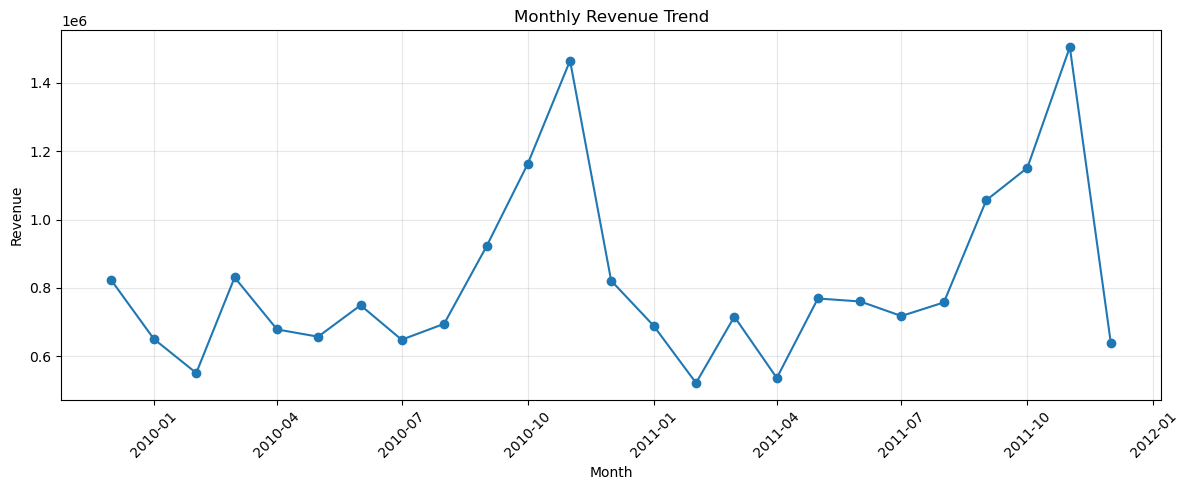

In [38]:
import matplotlib.pyplot as plt
import pandas as pd

query = """
SELECT
    strftime('%Y-%m', InvoiceDate) AS Month,
    ROUND(SUM(Quantity * Price), 2) AS Revenue
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY strftime('%Y-%m', InvoiceDate)
ORDER BY Month;
"""

monthly_revenue = pd.read_sql_query(query, conn)

monthly_revenue["Month"] = pd.to_datetime(monthly_revenue["Month"])

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_revenue["Month"],
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

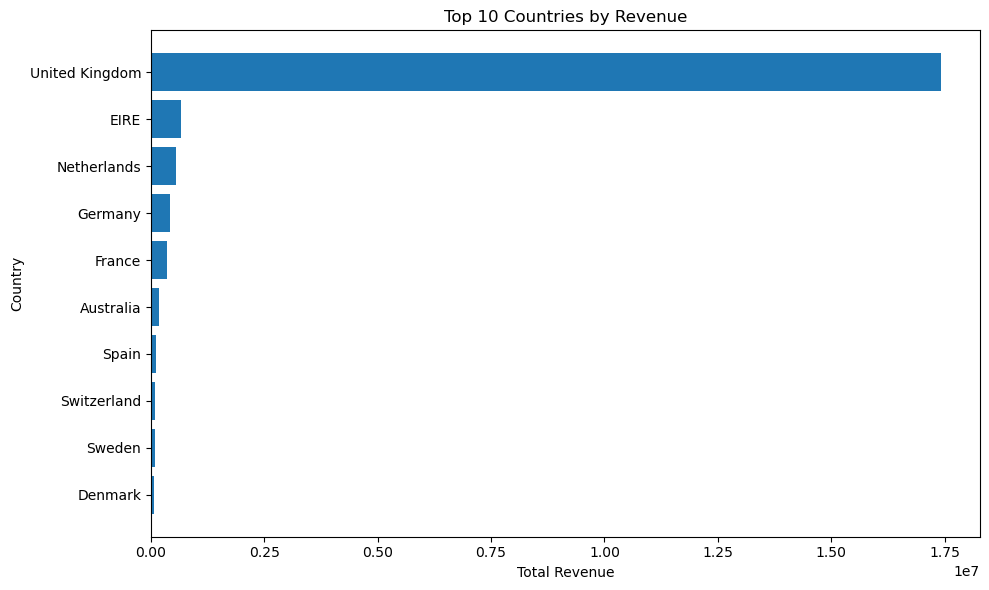

In [39]:
query = """
SELECT
    Country,
    ROUND(SUM(Quantity * Price), 2) AS Total_Revenue
FROM retail_transactions
WHERE Quantity > 0
  AND Price > 0
  AND CAST(Invoice AS TEXT) NOT LIKE 'C%'
GROUP BY Country
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

country_revenue = pd.read_sql_query(query, conn)

plt.figure(figsize=(10, 6))
plt.barh(
    country_revenue["Country"][::-1],
    country_revenue["Total_Revenue"][::-1]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()